<a id="import"></a>
# <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">Anomaly Detection Using Sklearn</p>

<div style="border-radius:10px; border:blue solid; padding: 15px; background-color: #E9EDF3; font-size:110%; text-align:left">
<a id="contents_table"></a>
<h3 align="left"><font color='blue'>Table of Contents:</font></h3>
    
* [What is Anomaly Detection?](#whatisanomaly)
* [Codes Using Sklearn](#sklearn)
    - [Import Libraries](#lib)
    - [Create Datasets](#datasets)
    - [Define a Function to Fit & Plot](#fnp)
    - [One Class SVM](#ocsvm)
    - [SGD One Class SVM](#sgd)
    - [Isolation Forest](#isolation)
    - [Elliptic Envelope](#elliptic)
    - [LOF (Local Outlier Factor)](#lof)
    - [DBSCAN](#dbscan)
* [PyOD](#pyod)
* [References](#ref)

<a id="whatisanomaly"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">What is Anomaly Detection?</p>
⬆️[Table of Contents](#contents_table)

<div style="border-radius:10px; border:blue solid; padding: 15px; background-color: #E9EDF3; font-size:110%; text-align:left">

<h2 align="left"><font color='blue'>Anomaly Detection</font></h2>
    
<p style="font-size:large">Anomaly detection is a technique used to identify data points in dataset that does not fit well with the rest of the data. It has many applications in business such as fraud detection, intrusion detection, system health monitoring, surveillance, and predictive maintenance. Anomalies, which are also called outlier, can be divided into following three categories: </p>

<p style="font-size:large">1.Point anomalies − It occurs when an individual data instance is considered as anomalous w.r.t the rest of the data. </p>
    <img src="./figs/global.png" width="300" height="300"/>

<p style="font-size:large">2.Contextual anomalies − Such kind of anomaly is context specific. It occurs if a data instance is anomalous in a specific context. </p>
    <img src="./figs/contextual.png" width="400" height="300"/>

<p style="font-size:large"> 3.Collective anomalies − It occurs when a collection of related data instances is anomalous w.r.t entire dataset rather than individual values. </p>
    <img src="./figs/collective.png" width="300" height="300"/>
    

<a id="sklearn"></a>
# <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">Codes Using Sklearn</p>
⬆️[Table of Contents](#contents_table)

<a id="lib"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">Import Libraries</p>
⬆️[Table of Contents](#contents_table)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import OneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.covariance import EllipticEnvelope
from sklearn.linear_model import SGDOneClassSVM
from sklearn.kernel_approximation import Nystroem
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons, make_blobs
from mlxtend.plotting import plot_decision_regions

<a id="datasets"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">Create Datasets</p>
⬆️[Table of Contents](#contents_table)

In [2]:
n_samples = 300
outliers_fraction = 0.15
n_outliers = int(outliers_fraction * n_samples)   # n_outliers = 45
n_inliers = n_samples - n_outliers                # n_inliers = 300-45 = 255

blobs_params = dict(n_samples=255 , n_features=2 , random_state=0 )

datasets = [make_blobs(centers=[[0, 0], [0, 0]]  , cluster_std=0.5       , **blobs_params)[0],
            make_blobs(centers=[[2, 2], [-2, -2]], cluster_std=[0.5, 0.5], **blobs_params)[0],
            make_blobs(centers=[[2, 2], [-2, -2]], cluster_std=[1.5, .3] , **blobs_params)[0],
            4. * (make_moons(n_samples=n_samples, noise=.05, random_state=0)[0] -np.array([0.5, 0.25])),
            14. * (np.random.RandomState(42).rand(n_samples, 2) - 0.5)]

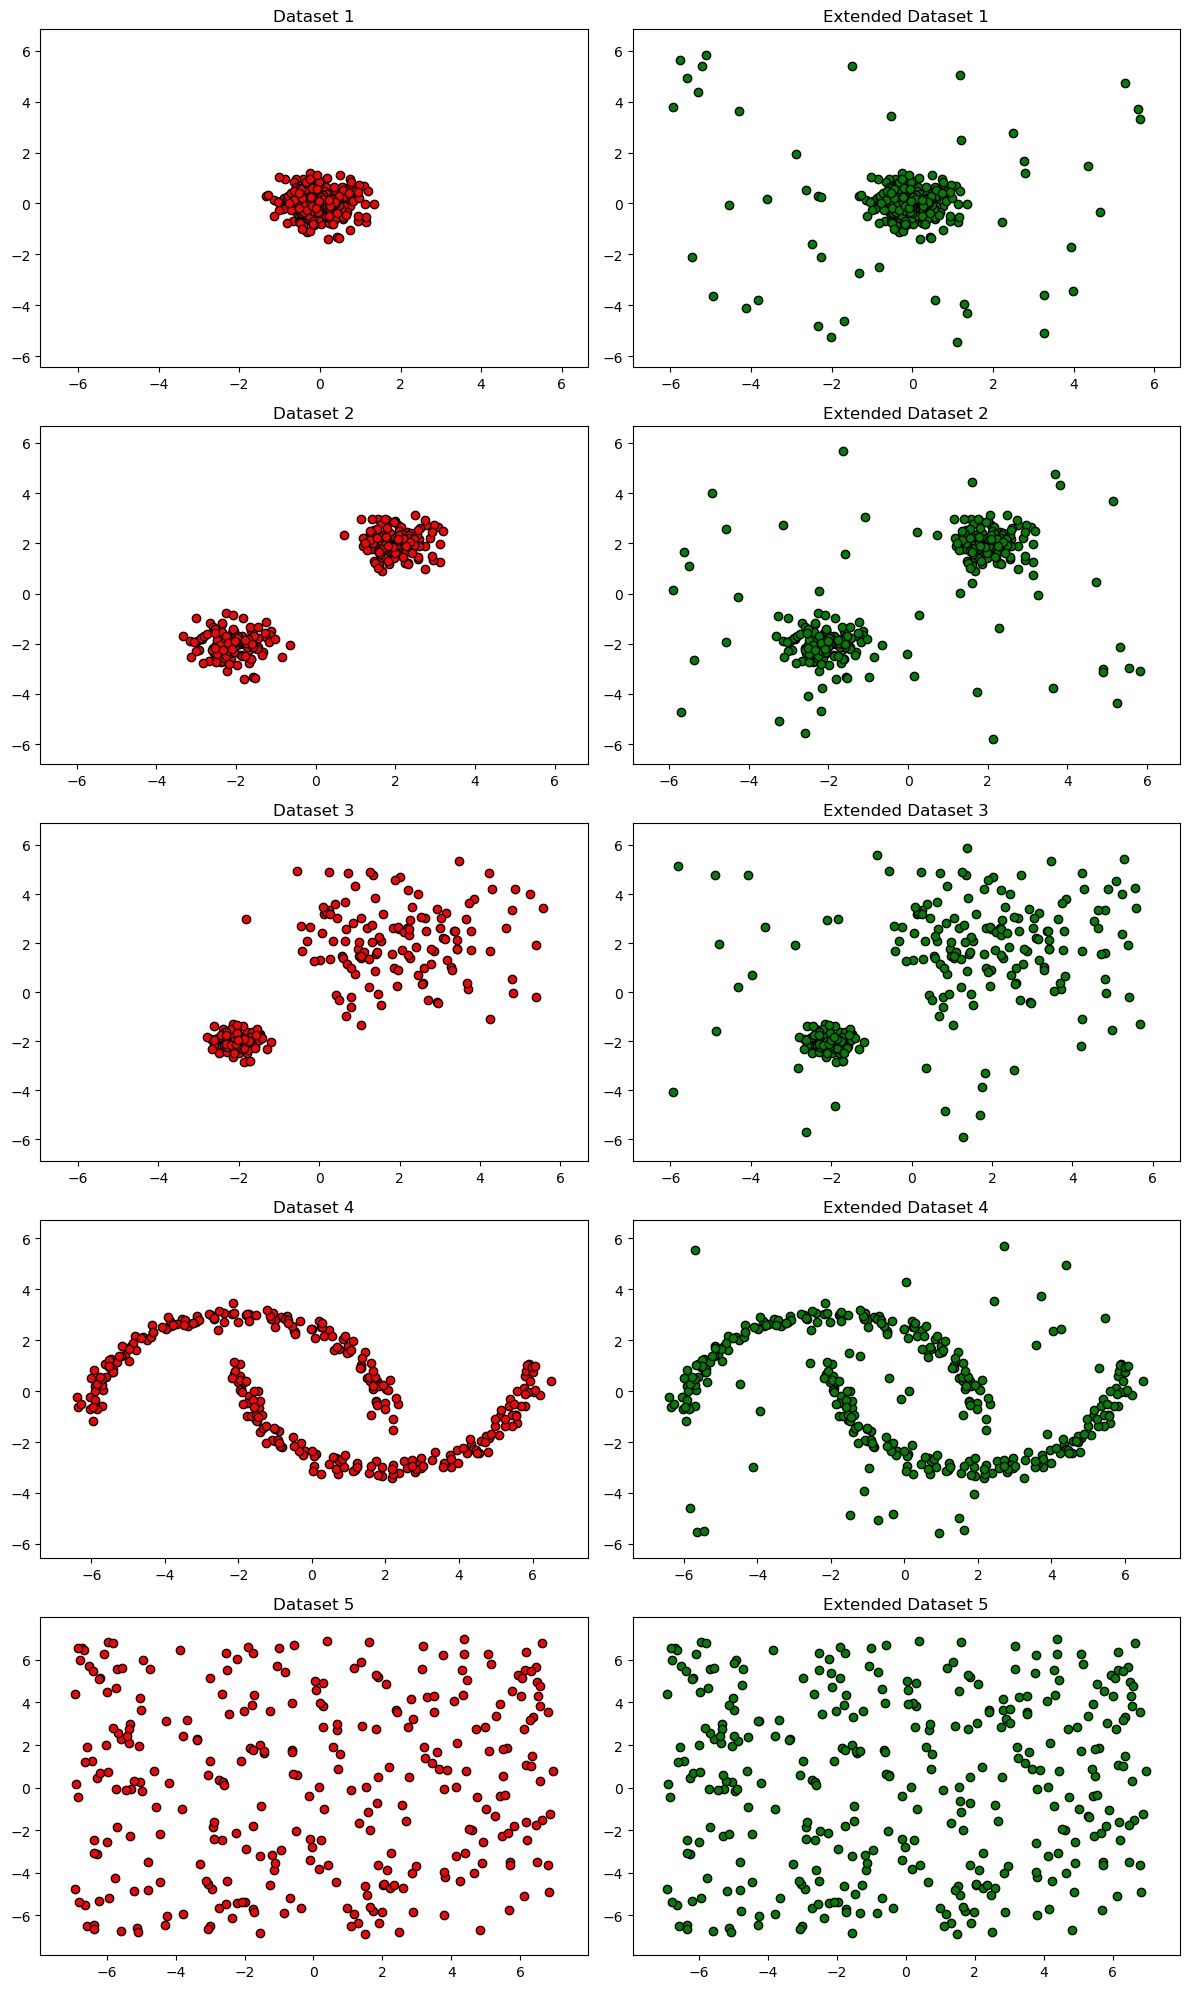

In [3]:
rng = np.random.RandomState(42)


fig, axs = plt.subplots(len(datasets), 2, figsize=(12, 4 * len(datasets)))

for i, dataset in enumerate(datasets):
    X = np.concatenate([dataset, rng.uniform(low=-6, high=6, size=(n_outliers, 2))], axis=0)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    axs[i, 0].scatter(dataset[:, 0], dataset[:, 1], c='r', edgecolors='k', label='Original Dataset')
    axs[i, 0].set_title(f'Dataset {i+1}')
    axs[i, 0].set_xlim(x_min, x_max)
    axs[i, 0].set_ylim(y_min, y_max)

    axs[i, 1].scatter(X[:, 0], X[:, 1], c='g', edgecolors='k', label='Extended Dataset')
    axs[i, 1].set_title(f'Extended Dataset {i+1}')
    axs[i, 1].set_xlim(x_min, x_max)
    axs[i, 1].set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

<a id="fnp"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">Define a Function to Fit & Plot</p>
⬆️[Table of Contents](#contents_table)

In [4]:
def fit_and_plot(datasets, model, plot_type, kernel=False, kernel_gamma=0.5, kernel_n_component=50):
    
    for i, dataset in enumerate(datasets):
        rng = np.random.RandomState(i)
        X = np.concatenate([dataset, rng.uniform(low=-6, high=6, size=(n_outliers, 2))], axis=0)
        
        if kernel:
            model = model
            feature_map_nystroem = Nystroem(gamma=kernel_gamma, random_state=1, n_components=kernel_n_component)
            X_transformed = feature_map_nystroem.fit_transform(X)
            model.fit(X_transformed)
            x_predicted = model.predict(X_transformed)


        else:
            model = model
            model.fit(X)
            x_predicted = model.predict(X)

        plt.figure(figsize=(12, 4))
        x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
        
        if plot_type == 'contour' or kernel:
            x_ = np.linspace(x_min, x_max, 500)
            y_ = np.linspace(y_min, y_max, 500)

            xx, yy = np.meshgrid(x_, y_)
            if kernel:
                meshgrid_transformed = feature_map_nystroem.transform(np.c_[xx.ravel(), yy.ravel()])
                z = model.decision_function(meshgrid_transformed)
                z = z.reshape(xx.shape)
            else:
                z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
                z = z.reshape(xx.shape)

            plt.subplot(1, 2, 1)
            plt.contourf(xx, yy, z, cmap=plt.cm.PuBu)
            a = plt.contour(xx, yy, z, levels=[0], linewidths=2, colors='darkred')
            b = plt.scatter(X[x_predicted == 1, 0], X[x_predicted == 1, 1], c='white', edgecolors='k')
            c = plt.scatter(X[x_predicted == -1, 0], X[x_predicted == -1, 1], c='gold', edgecolors='k')
            plt.legend([b, c], [ '1', '-1'])
            plt.axis('tight')
            plt.title(f'Dataset {i+1} - Decision Regions')

        elif plot_type == 'dr':
            plt.subplot(1, 2, 1)
            plot_decision_regions(X, x_predicted, clf=model)
            plt.title(f'Dataset {i+1} - Decision Regions')

        plt.subplot(1, 2, 2)
        plt.scatter(dataset[:, 0], dataset[:, 1], c='r', edgecolors='k', label='Original Dataset')
        plt.xlim(x_min, x_max)
        plt.ylim(y_min, y_max)
        plt.title(f'Dataset {i+1} - Original Dataset')

        plt.tight_layout()
        plt.show()


<a id="ocsvm"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">One Class SVM</p>
⬆️[Table of Contents](#contents_table)

<img src="./figs/oneclasssvm.jpg"/>

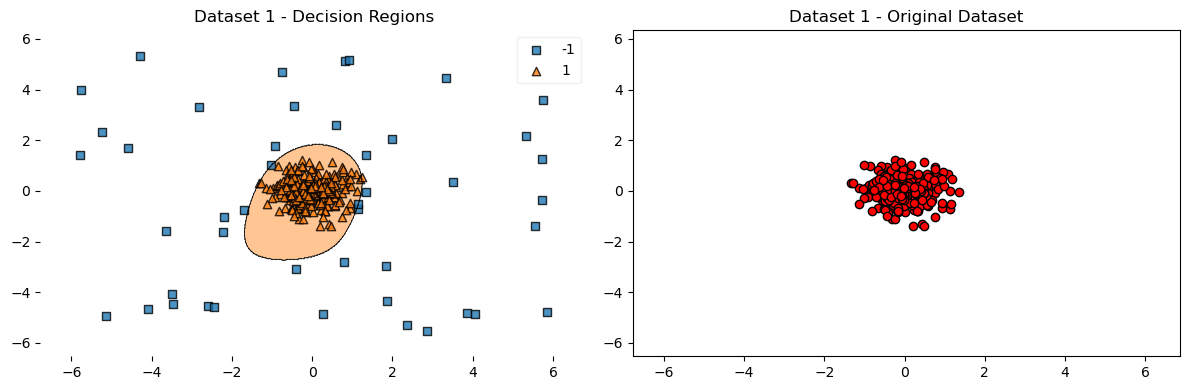

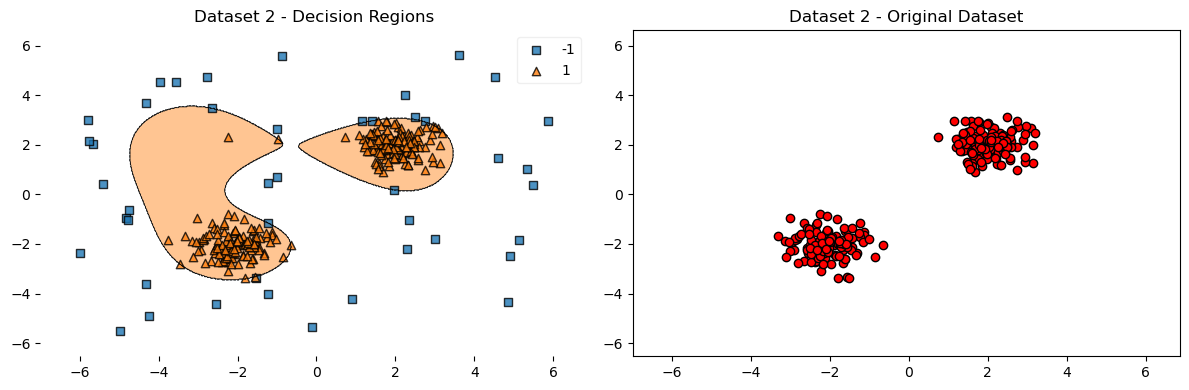

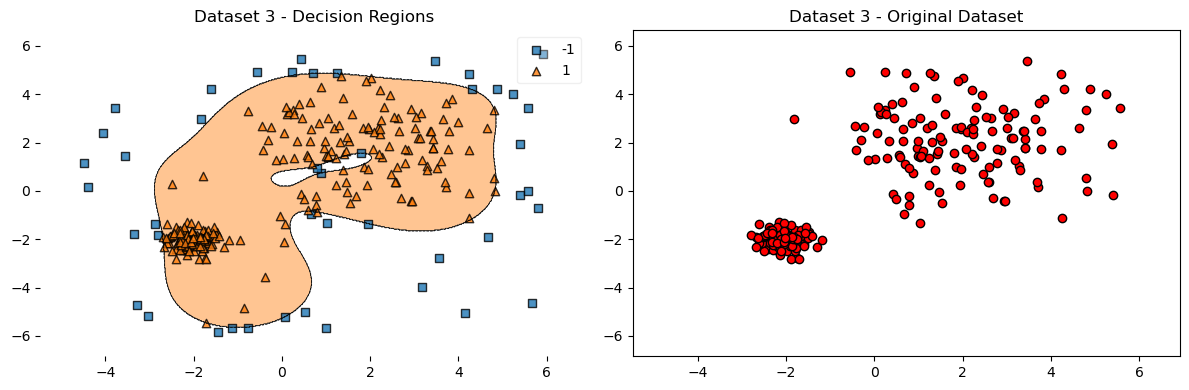

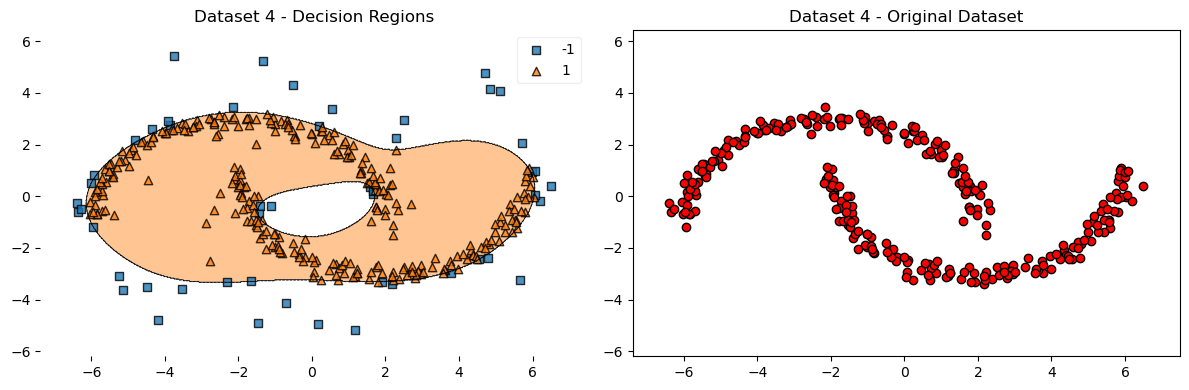

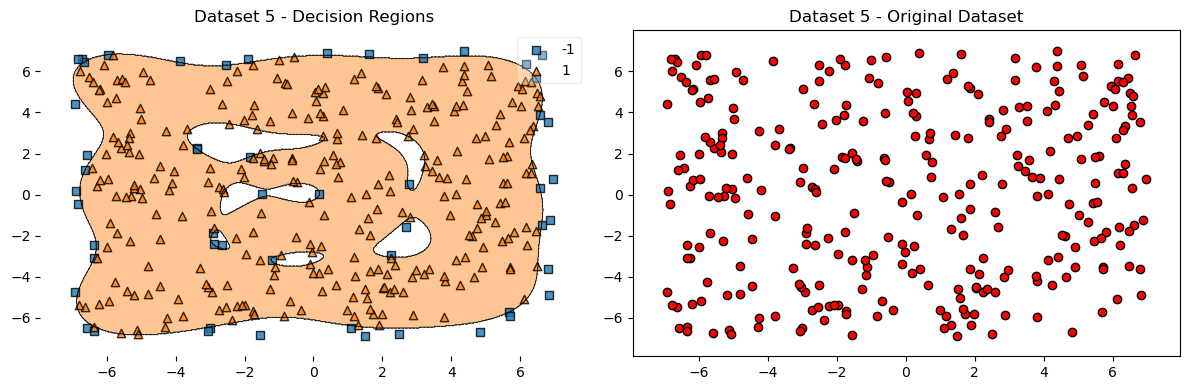

In [5]:
model = OneClassSVM(kernel="rbf", nu=outliers_fraction, gamma=0.1)
fit_and_plot(datasets, model, 'dr')

In [6]:
X = [[0], [0.44], [0.45], [0.46], [1]]
clf = OneClassSVM(gamma='auto').fit(X)
print(clf.predict(X))
print(clf.decision_function(X))

[-1  1  1  1 -1]
[-2.74925564e-01  5.28455635e-09  8.06251090e-04  1.35696904e-03
 -3.21513634e-01]


<Axes: >

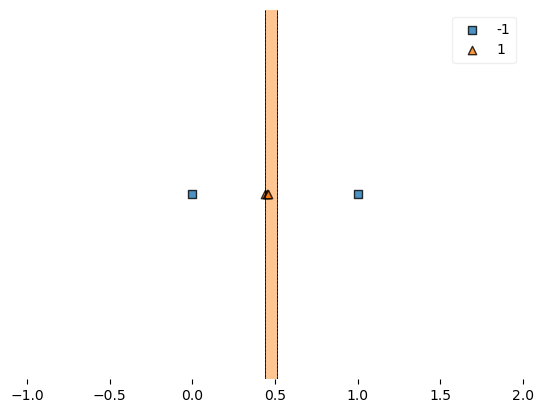

In [7]:
plot_decision_regions(np.array(X), clf.predict(X), clf)

<a id="sgd"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">SGD One Class SVM</p>
⬆️[Table of Contents](#contents_table)

<img src="./figs/sgdone.jpg"/>

<img src="./figs/nystroem.jpg"/>

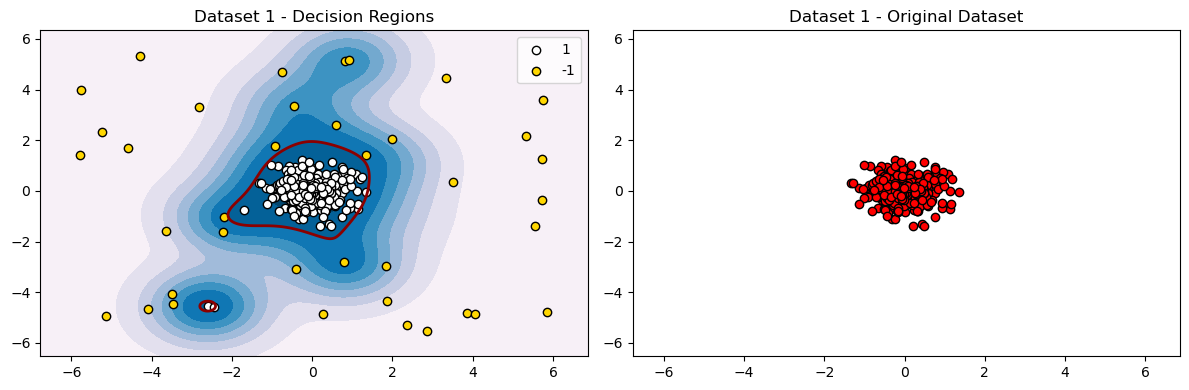

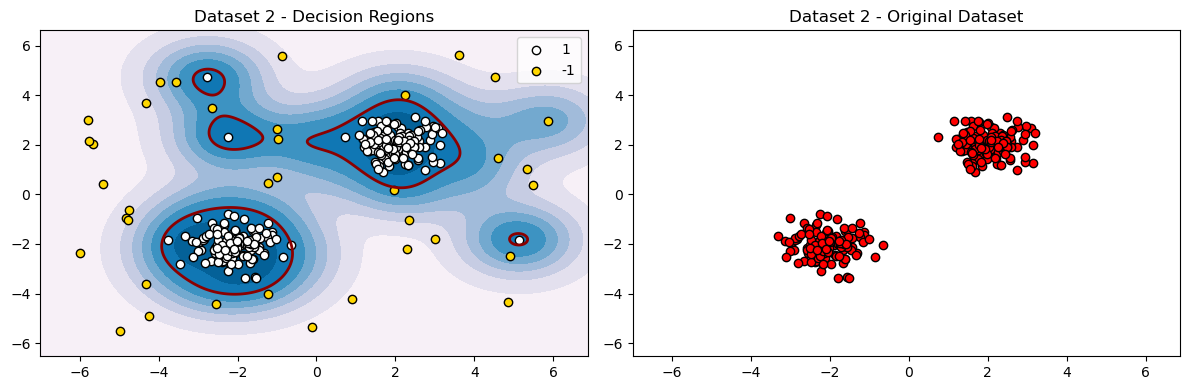

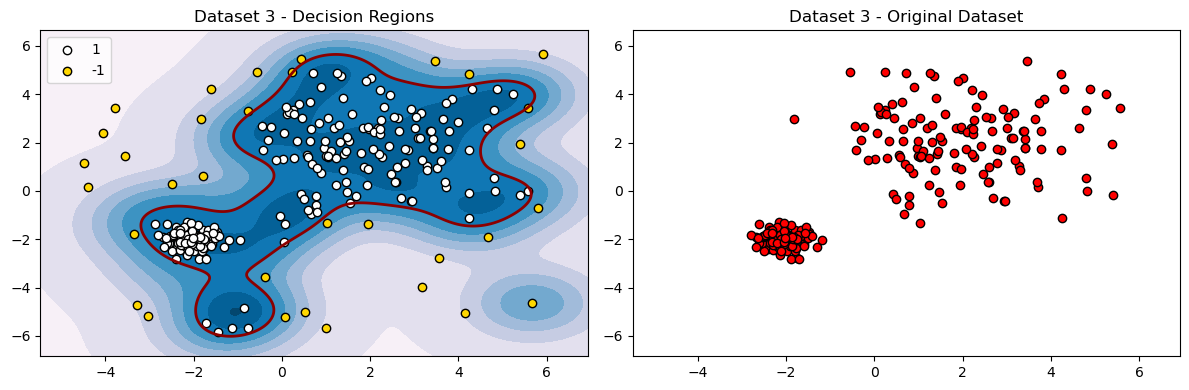

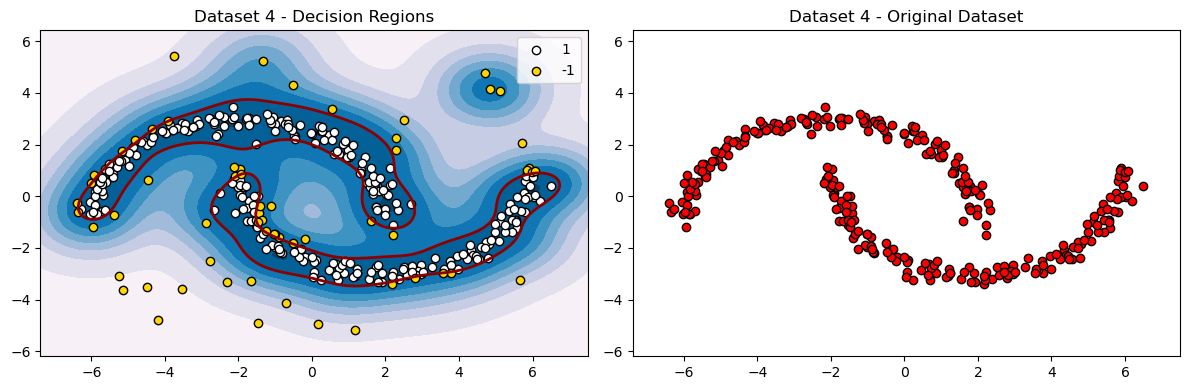

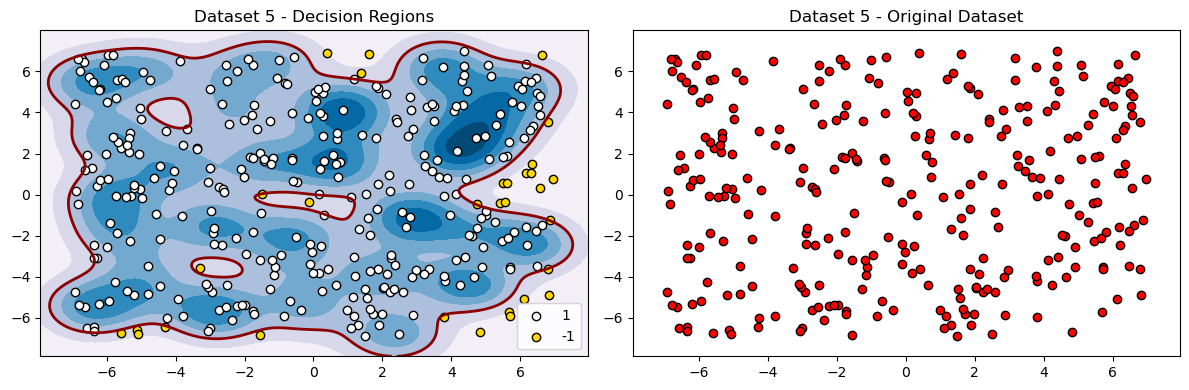

In [8]:
model = SGDOneClassSVM(nu=outliers_fraction, random_state=0)
fit_and_plot(datasets, model, 'contour', kernel=True)

In [9]:
X = np.array([[0, 0], [0, 2], [2, 0], [2,2]])
model = SGDOneClassSVM(random_state=42)
model.fit(X)
print(model.predict([[7, 6]]))
print(model.predict([[0.5, 0.5]]))

[1]
[-1]


<img src="./figs/sgddf.jpg"/>

In [10]:
print(model.decision_function([[7,6]]))
print(model.decision_function([[0.5,0.5]]))

[7.17271957]
[-0.26095028]


<a id="isolation"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">Isolation Forest</p>
⬆️[Table of Contents](#contents_table)

<img src="./figs/isolation.jpg"/>

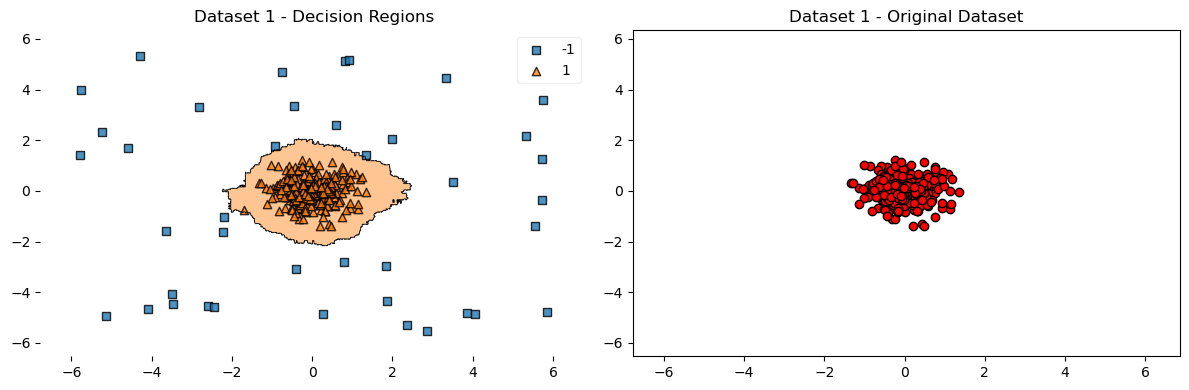

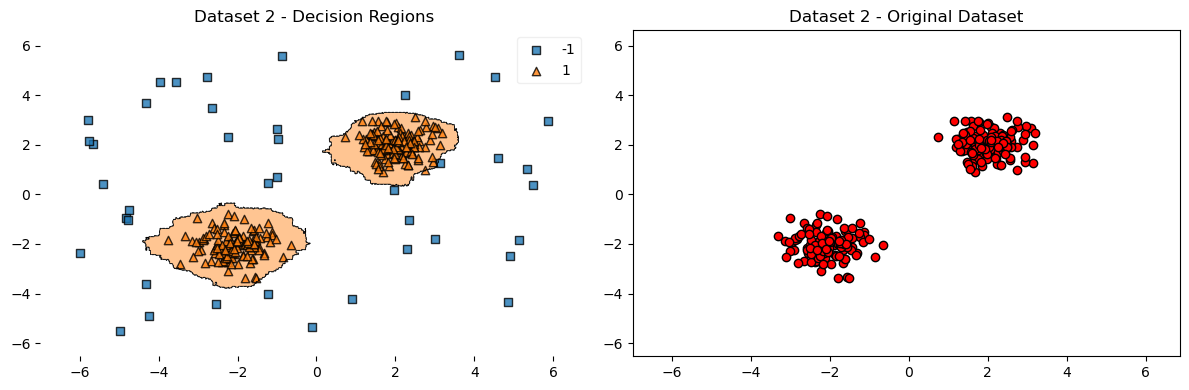

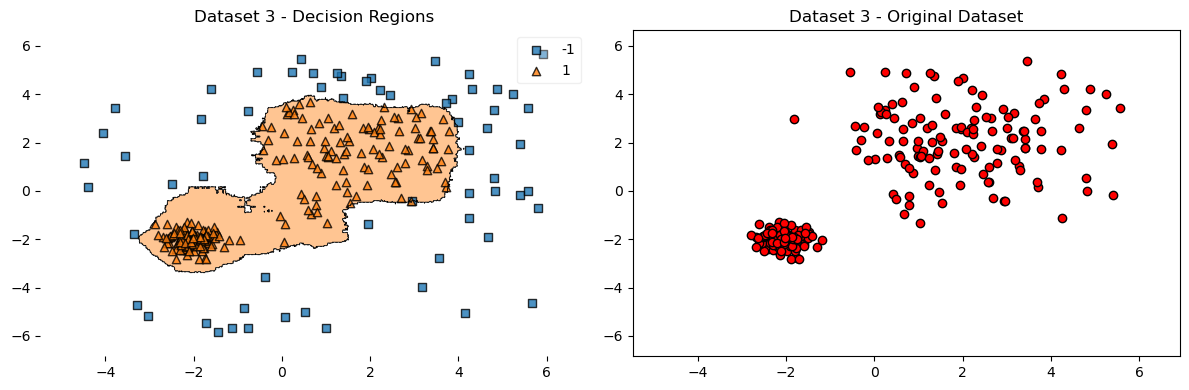

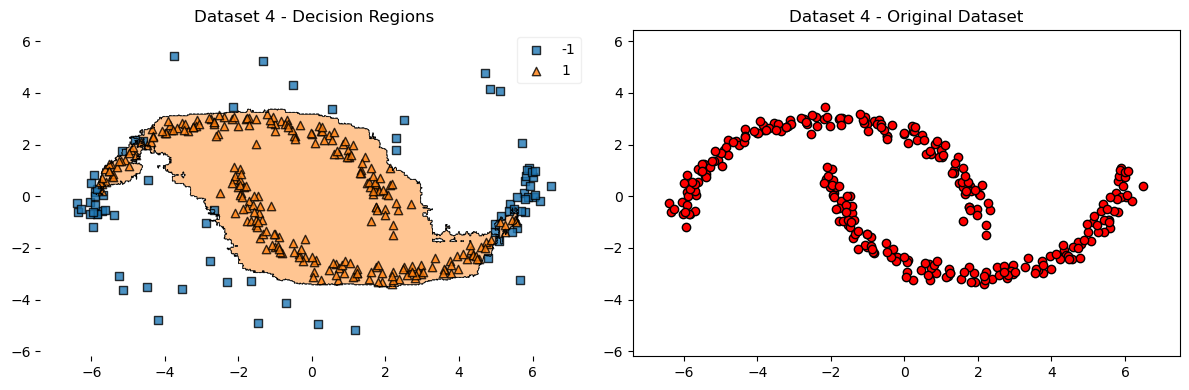

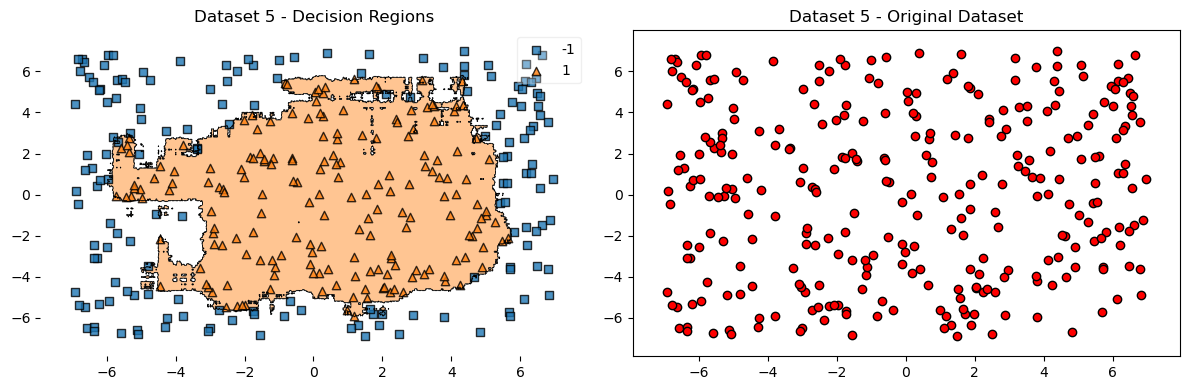

In [11]:
model = IsolationForest(n_estimators=100, random_state=0)
fit_and_plot(datasets, model, 'dr')

In [12]:
X = [[1.1], [0.3], [0.5], [0.8], [0.4], [100]]
clf = IsolationForest(random_state=0).fit(X)
clf.predict([[0.1], [0], [90]])

array([ 1,  1, -1])

<Axes: >

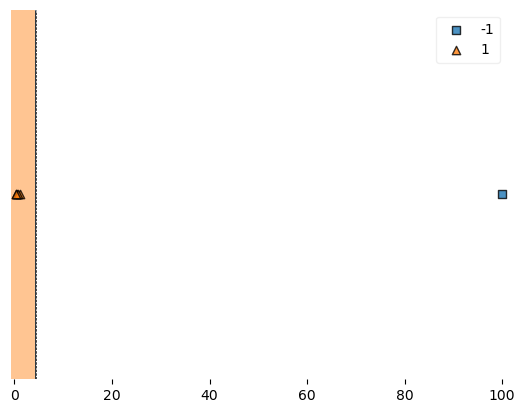

In [13]:
plot_decision_regions(np.array(X), clf.predict(X), clf)

In [14]:
#Average anomaly score of X of the base classifiers.
print(clf.decision_function([[0.1], [0], [90]]))

[ 0.07129178  0.07129178 -0.23542288]


<a id="elliptic"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">Elliptic Envelope</p>
⬆️[Table of Contents](#contents_table)

<img src="./figs/elliptic.jpg"/>

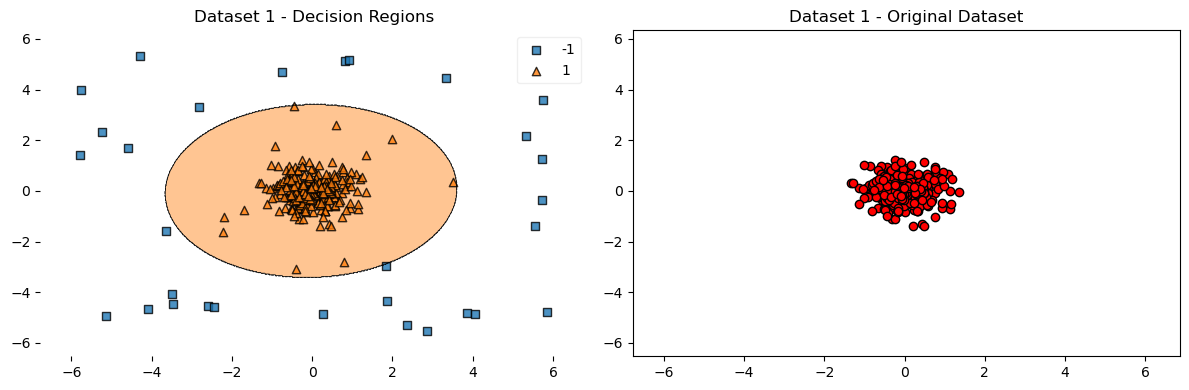

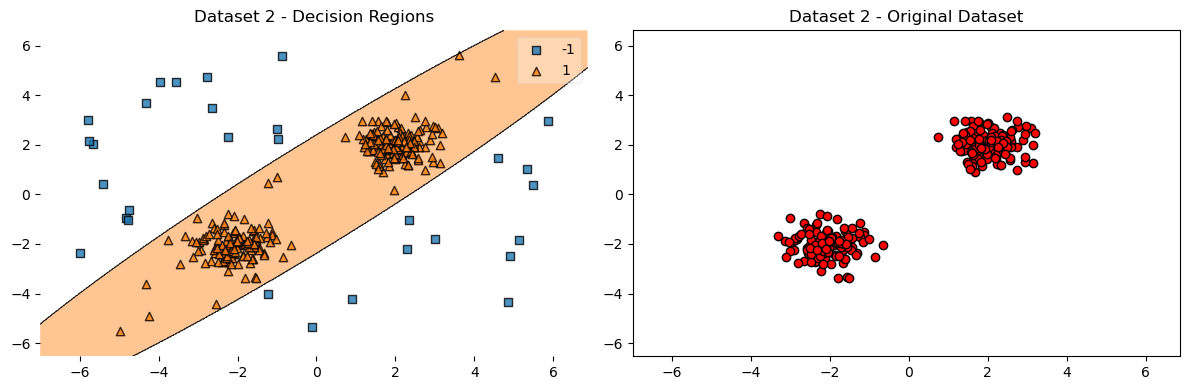

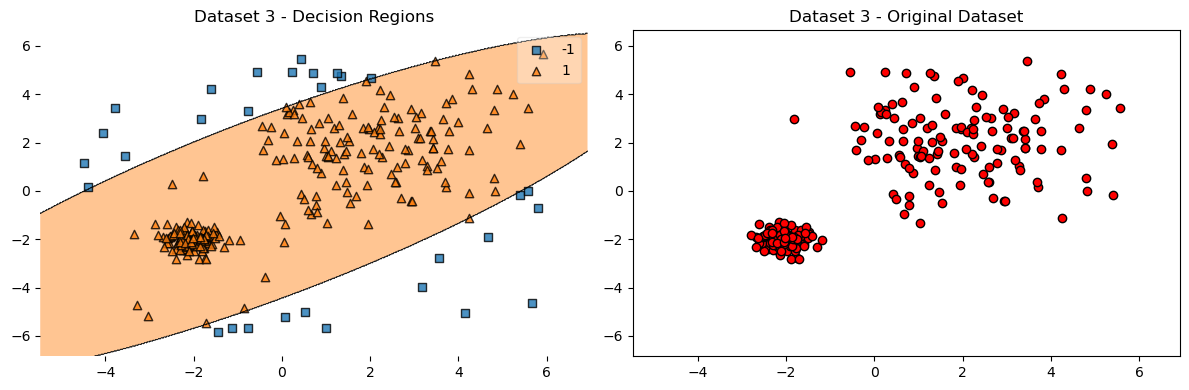

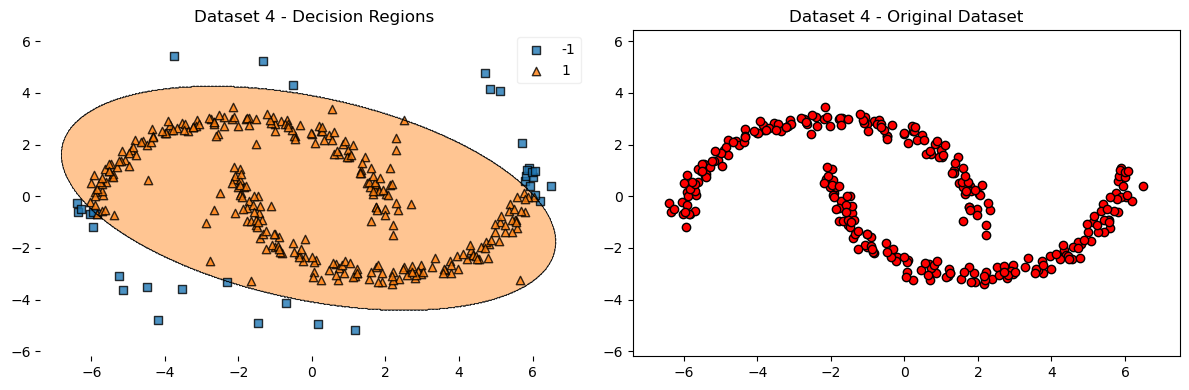

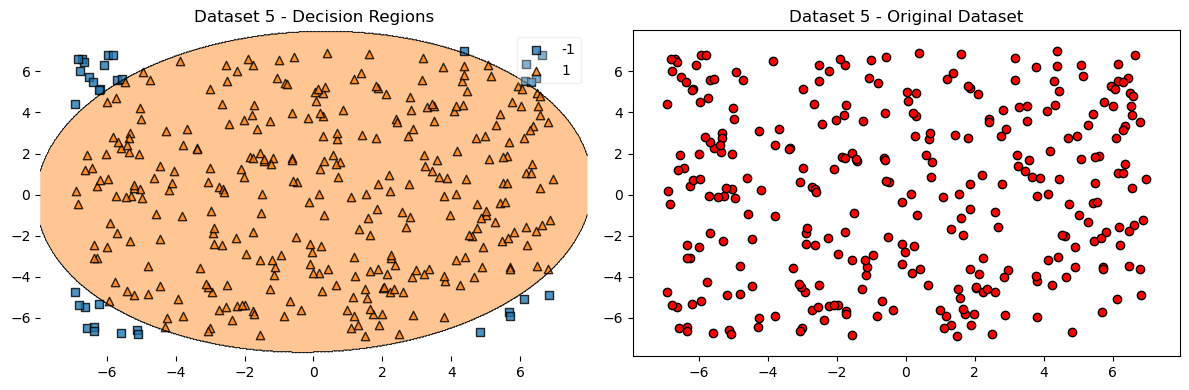

In [15]:
model = EllipticEnvelope(random_state=0)
fit_and_plot(datasets, model, 'dr')

In [16]:
true_cov = np.array([[.8, .3],
                     [.3, .4]])
X = np.random.RandomState(0).multivariate_normal(mean=[0, 0],
                                                 cov=true_cov,
                                                 size=500)
cov = EllipticEnvelope(random_state=0).fit(X)
# predict returns 1 for an inlier and -1 for an outlier
cov.predict([[0, 0],
             [2, -1.5]])

array([ 1, -1])

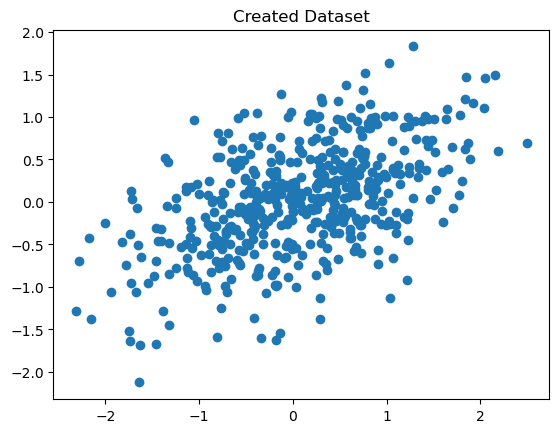

In [17]:
plt.title('Created Dataset')
plt.scatter(X[:, 0], X[:, 1]);

<Axes: >

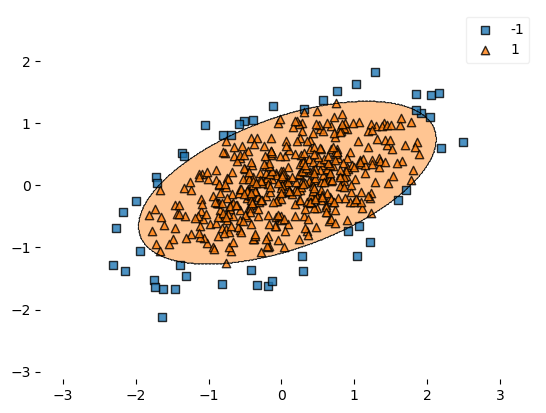

In [18]:
plot_decision_regions(X, cov.predict(X), cov)

In [19]:
cov.mahalanobis([[0,0],
                [2,-1.5]])

array([9.95419647e-03, 2.70949641e+01])

<a id="lof"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">LOF (Local Outlier Factor)</p>
⬆️[Table of Contents](#contents_table)

<img src="./figs/lof1.jpg"/>
<img src="./figs/lof2.jpg"/>

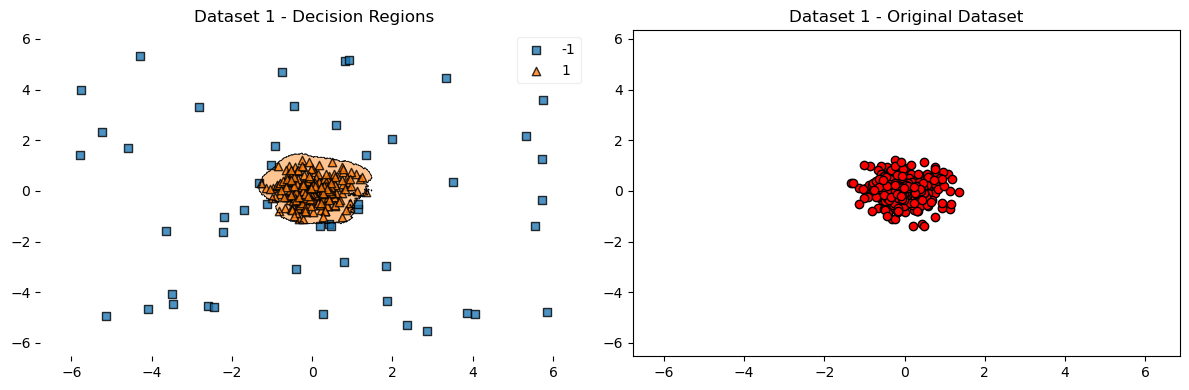

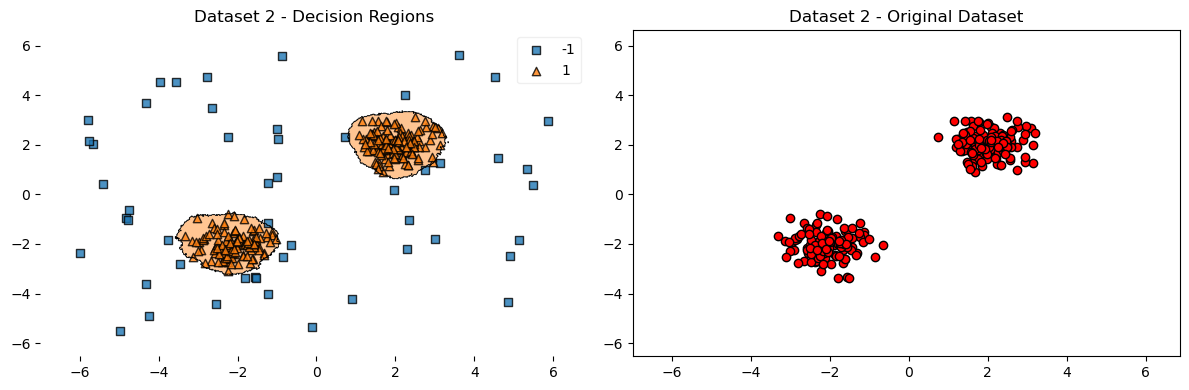

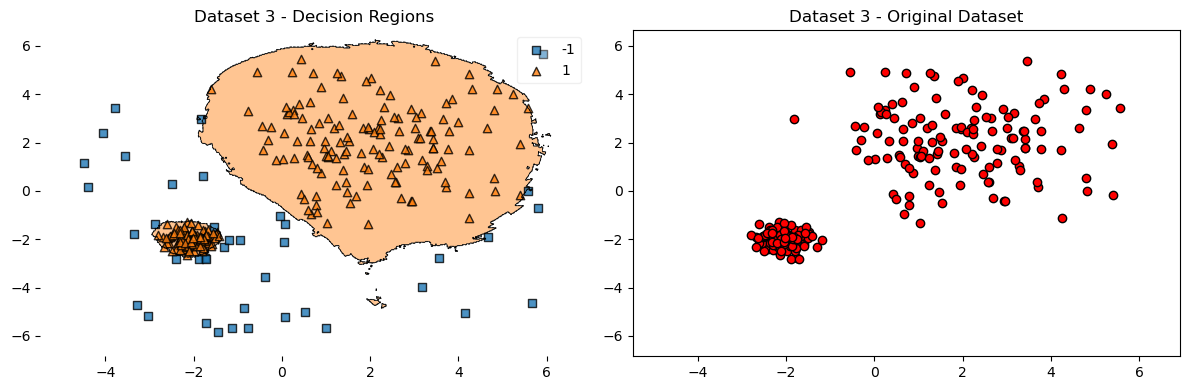

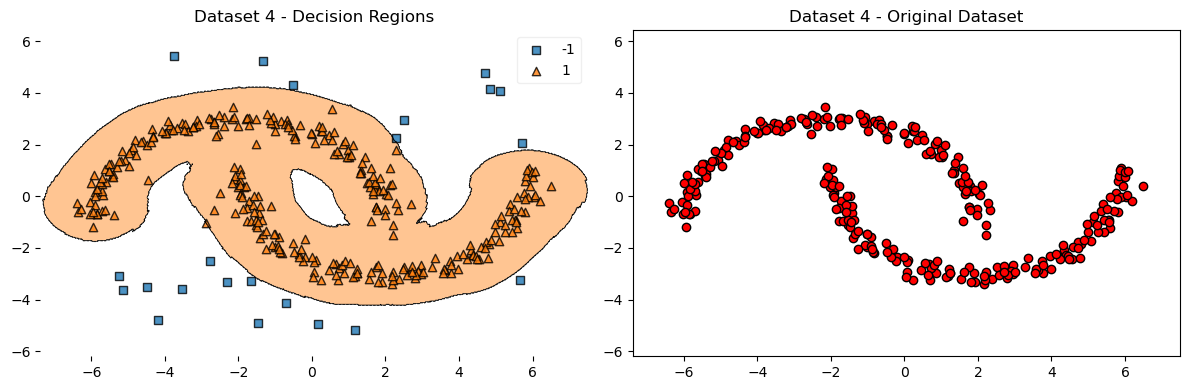

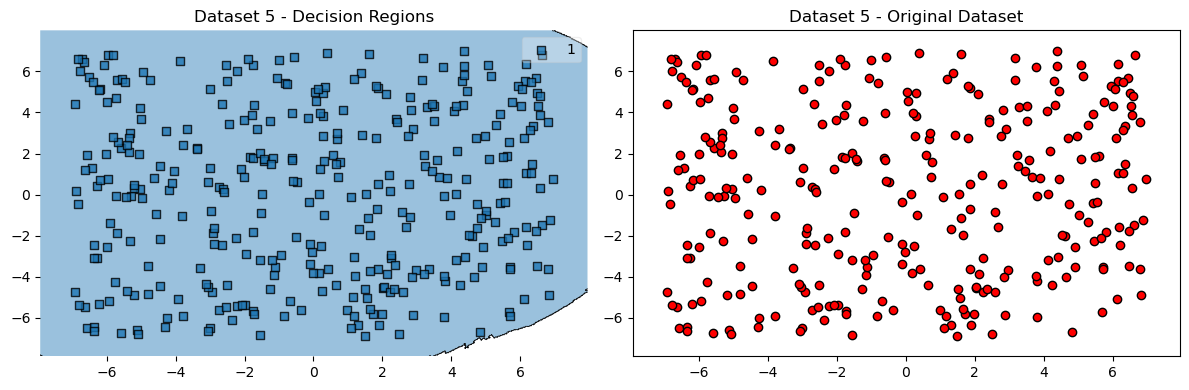

In [20]:
model = LocalOutlierFactor(n_neighbors=20, novelty=True)
fit_and_plot(datasets, model, 'dr')

In [21]:
X = [[-1.1], [0.2], [101.1], [0.3]]
model = LocalOutlierFactor(n_neighbors=2)
model.fit_predict(X)
model.negative_outlier_factor_

array([ -0.98214286,  -1.03703704, -73.36970899,  -0.98214286])

<a id="dbscan"></a>
## <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">DBSCAN</p>
⬆️[Table of Contents](#contents_table)

<img src="./figs/nearestneighbors.jpg"/>
<img src="./figs/dbscan.jpg"/>

In [22]:
def DBSCAN_fit_and_plot(datasets, i, model, eps, min_samples):
    rng = np.random.RandomState(i)
    X = np.concatenate([datasets[i], rng.uniform(low=-6, high=6, size=(n_outliers, 2))], axis=0)
    
    model.fit(X)
    colors = model.labels_
    
    
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.title(f'Dataset {i+1} - DBSCAN Results (epsilon={eps}, min samples = {min_samples})')
    plt.scatter(X[:,0], X[:,1], c = colors)

    plt.subplot(1, 2, 2)
    plt.scatter(datasets[i][:, 0], datasets[i][:, 1], c='r', edgecolors='k', label='Original Dataset')
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.title(f'Dataset {i+1} - Original Dataset')

    
def nn_fit_and_plot(datasets, i, n_neighbors):
    rng = np.random.RandomState(i)
    X = np.concatenate([datasets[i], rng.uniform(low=-6, high=6, size=(n_outliers, 2))], axis=0)    
    
    neigh = NearestNeighbors(n_neighbors = n_neighbors)
    nbrs = neigh.fit(X)
    distances, indices = nbrs.kneighbors(X)

    distances = np.sort(distances, axis=0)
    distances = distances[:,1]
    plt.figure(figsize=(8,5))
    plt.plot(distances)
    plt.title(f'K-distance Graph for Dataset {i+1}')
    plt.xlabel('Data Points sorted by distance')
    plt.ylabel('Epsilon')
    plt.show()

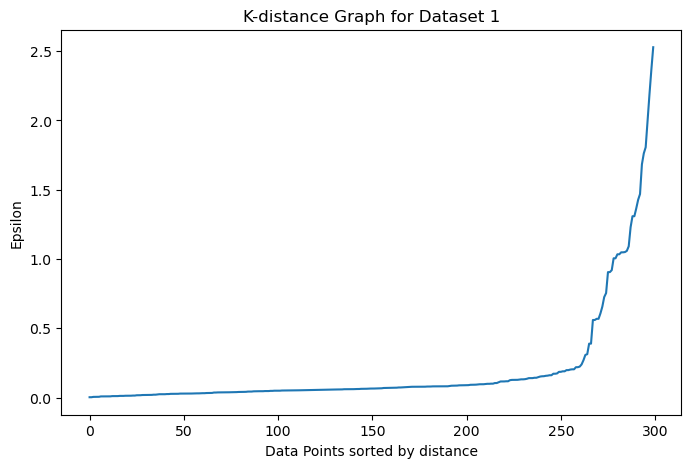

In [23]:
nn_fit_and_plot(datasets, 0, 4)

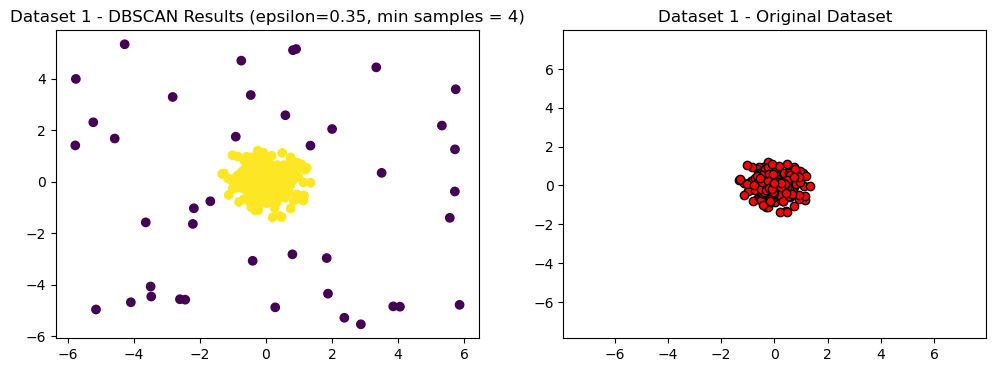

In [24]:
model = DBSCAN(eps=0.35, min_samples=4)
DBSCAN_fit_and_plot(datasets, 0, model, model.eps, model.min_samples)

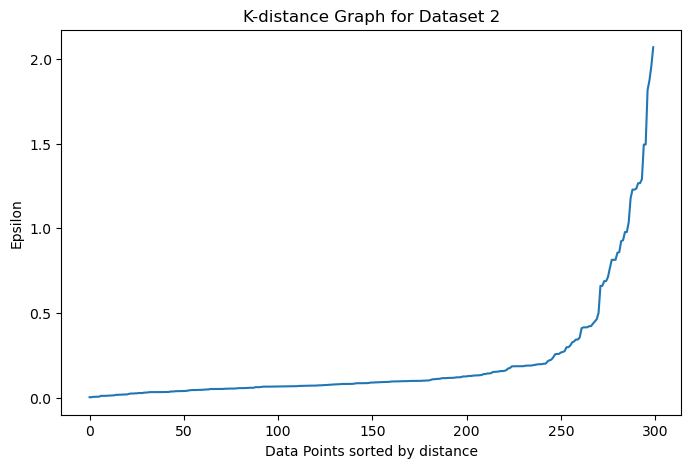

In [25]:
nn_fit_and_plot(datasets, 1, 4)

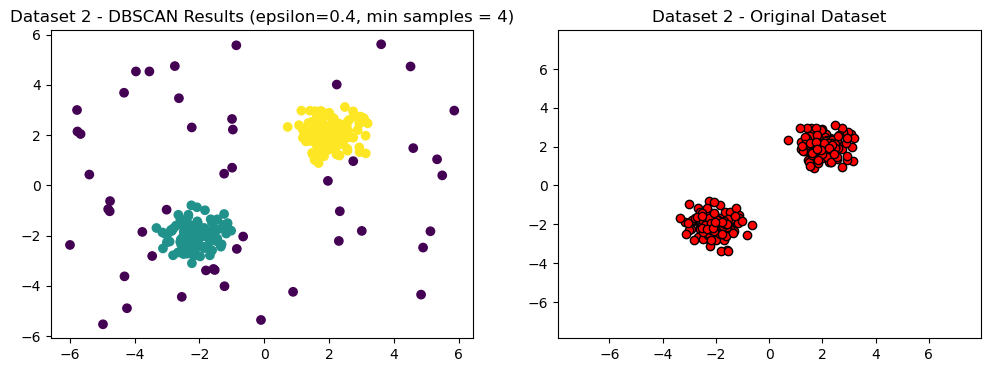

In [26]:
model = DBSCAN(eps=0.4, min_samples=4)
DBSCAN_fit_and_plot(datasets, 1, model, model.eps, model.min_samples)

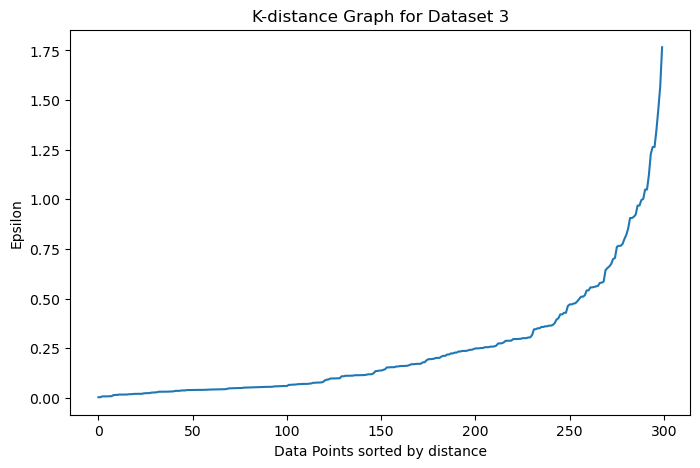

In [27]:
nn_fit_and_plot(datasets, 2, 8)

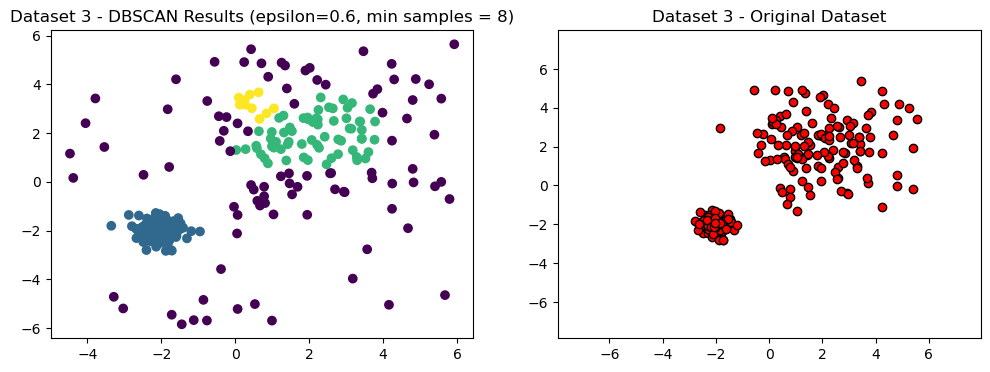

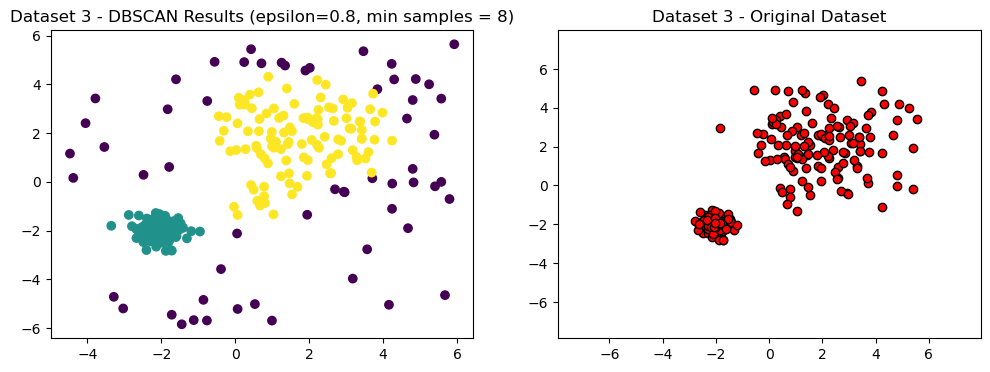

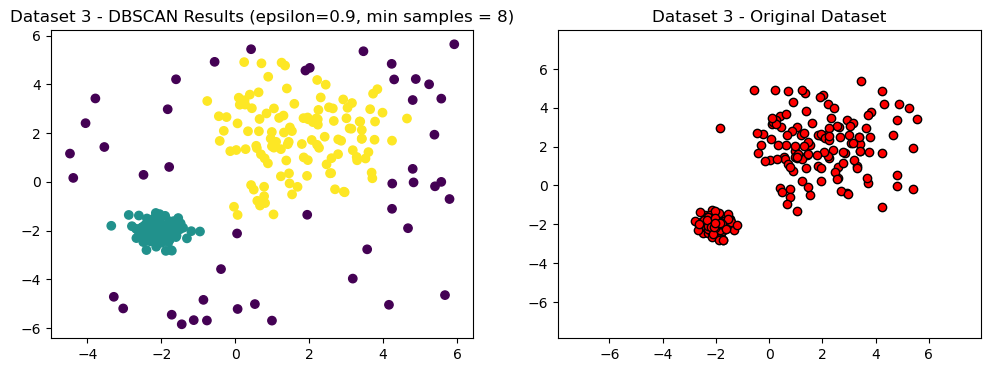

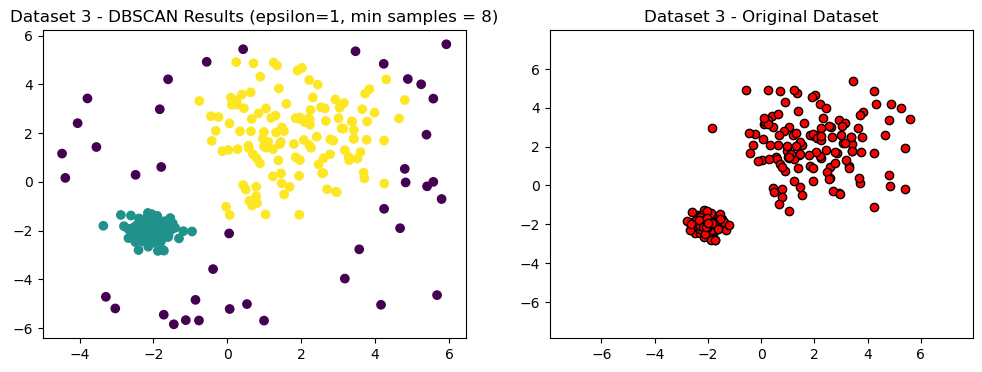

In [28]:
model = DBSCAN(eps=0.6, min_samples=8)
DBSCAN_fit_and_plot(datasets, 2, model, model.eps, model.min_samples)
model = DBSCAN(eps=0.8, min_samples=8)
DBSCAN_fit_and_plot(datasets, 2, model, model.eps, model.min_samples)
model = DBSCAN(eps=0.9, min_samples=8)
DBSCAN_fit_and_plot(datasets, 2, model, model.eps, model.min_samples)
model = DBSCAN(eps=1, min_samples=8)
DBSCAN_fit_and_plot(datasets, 2, model, model.eps, model.min_samples)

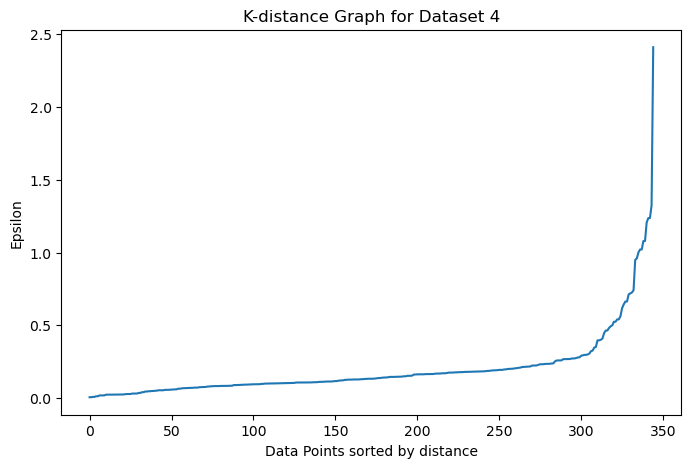

In [29]:
nn_fit_and_plot(datasets, 3, 5)

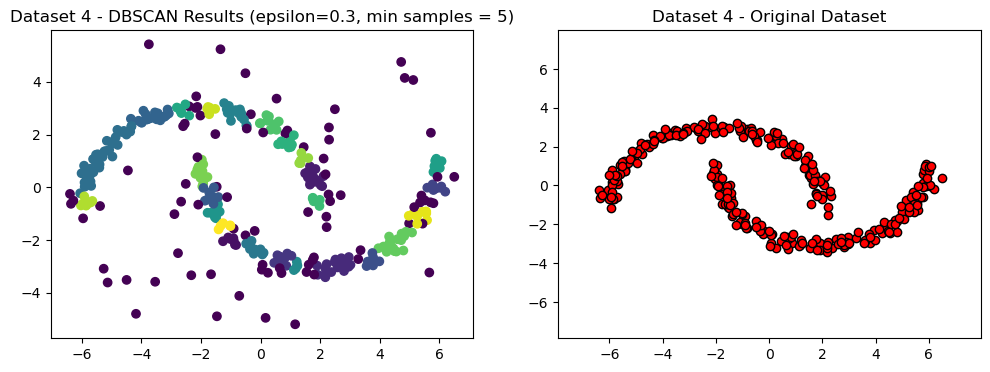

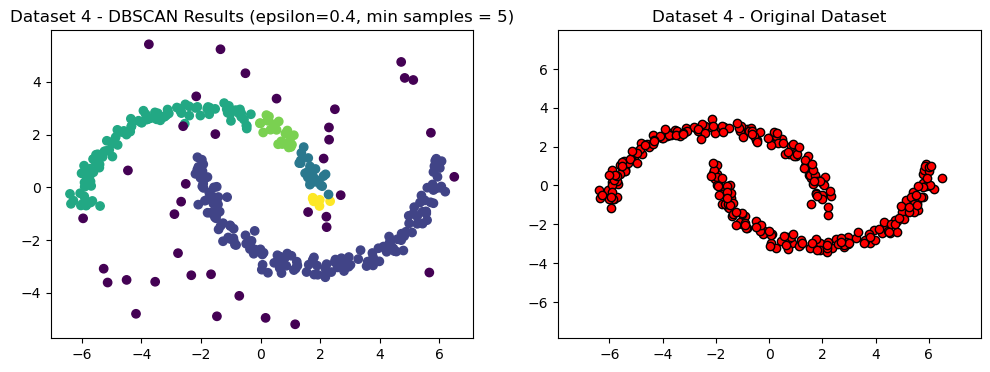

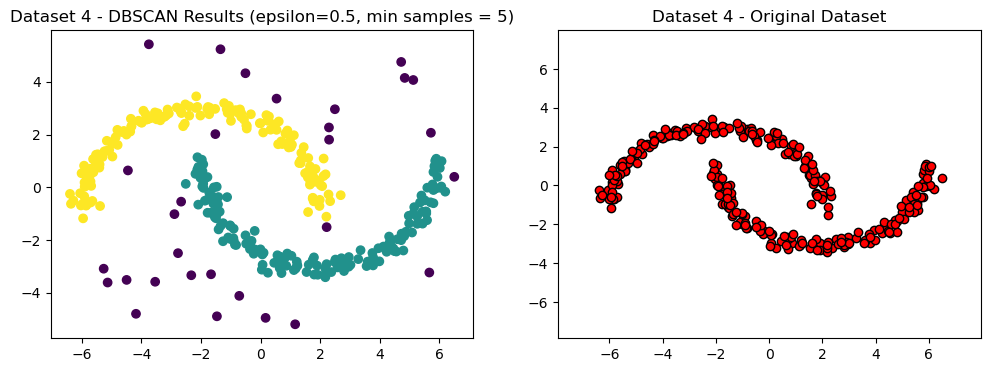

In [30]:
model = DBSCAN(eps=0.3, min_samples=5)
DBSCAN_fit_and_plot(datasets, 3, model, model.eps, model.min_samples)
model = DBSCAN(eps=0.4, min_samples=5)
DBSCAN_fit_and_plot(datasets, 3, model, model.eps, model.min_samples)
model = DBSCAN(eps=0.5, min_samples=5)
DBSCAN_fit_and_plot(datasets, 3, model, model.eps, model.min_samples)

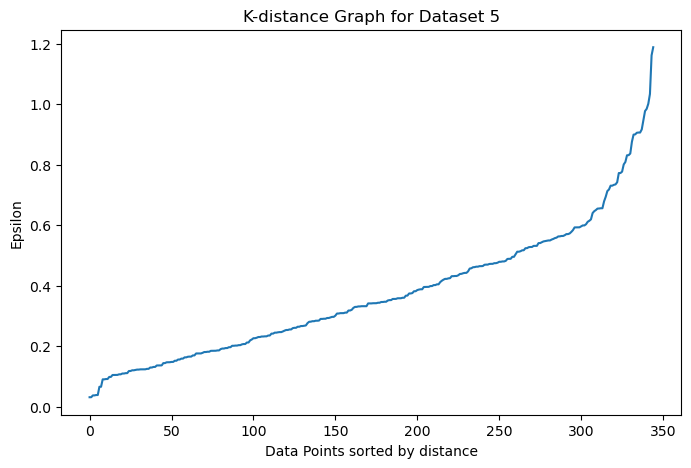

In [31]:
nn_fit_and_plot(datasets, 4, 5)

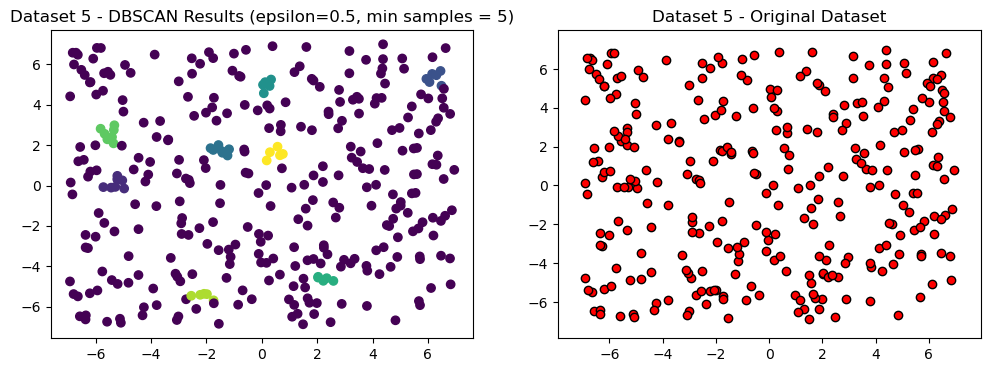

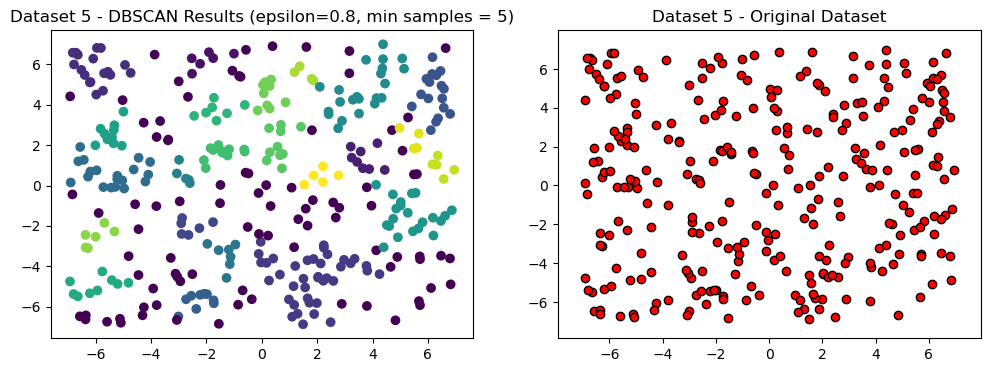

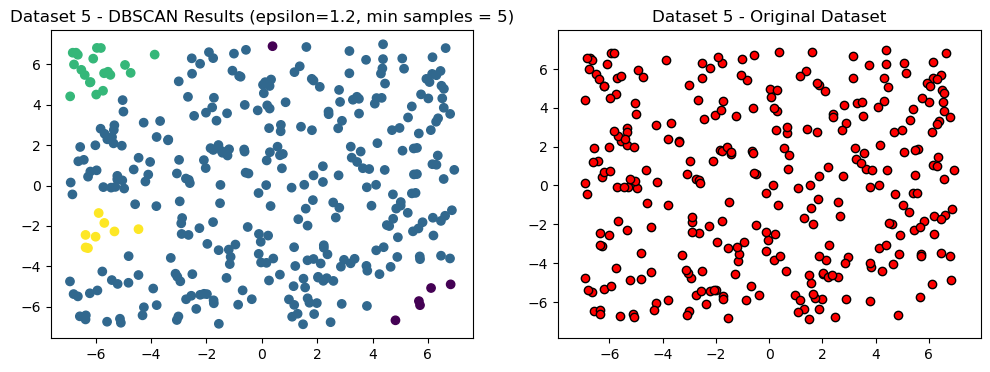

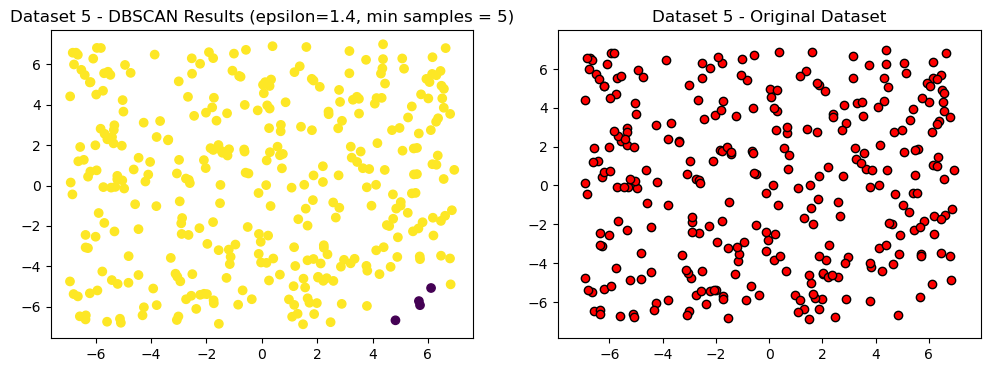

In [32]:
model = DBSCAN(eps=0.5, min_samples=5)
DBSCAN_fit_and_plot(datasets, 4, model, model.eps, model.min_samples)
model = DBSCAN(eps=0.8, min_samples=5)
DBSCAN_fit_and_plot(datasets, 4, model, model.eps, model.min_samples)
model = DBSCAN(eps=1.2, min_samples=5)
DBSCAN_fit_and_plot(datasets, 4, model, model.eps, model.min_samples)
model = DBSCAN(eps=1.4, min_samples=5)
DBSCAN_fit_and_plot(datasets, 4, model, model.eps, model.min_samples)

<a id="pyod"></a>
# <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">PyOD</p>
⬆️[Table of Contents](#contents_table)

<img src="./figs/pyod.jpg"/>

<img src="./figs/pyod.png" width="1200" height="1200"/>

<a id="ref"></a>
# <p style="background-color:midnightblue; font-family:calibri; font-size:130%; color:white; text-align:center; border-radius:10px 10px; padding:15px">References</p>
⬆️[Table of Contents](#contents_table)

* https://www.tutorialspoint.com/scikit_learn/scikit_learn_anomaly_detection.htm
* https://scikit-learn.org/0.21/auto_examples/plot_anomaly_comparison.html
* https://pyod.readthedocs.io
* https://scikit-learn.org
* https://medium.com/@dilip.voleti/dbscan-algorithm-for-fraud-detection-outlier-detection-in-a-data-set-60a10ad06ea8